# Scalar vs vector micrograd

Sanity check that the two engines compute the same thing. We build the same MLP in both, with the vector engine's random weights copied into the scalar one. Then we check that:

1. the forward pass gives the same loss
2. the backward pass gives the same gradient for every parameter
3. a few steps of SGD follow the same loss curve

Finally, a quick timing comparison shows why the vector version exists.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from zero_to_hero.part_01_micrograd.micrograd_scalar.engine import Value as SValue
from zero_to_hero.part_01_micrograd.micrograd_scalar.nn import MLP as SMLP
from zero_to_hero.part_01_micrograd.micrograd_vector.engine import Value as VValue
from zero_to_hero.part_01_micrograd.micrograd_vector.nn import MLP as VMLP

## Data and models

A tiny regression problem, the same one as in the lecture: 4 samples with 3 features each.

The target `ys` for the vector engine has shape `(N, 1)`, not `(N,)`. The MLP output is `(N, 1)`, and subtracting a `(N,)` target would broadcast the result to `(N, N)`.

In [2]:
xs = np.array([
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0],
])
ys = np.array([[1.0], [-1.0], [-1.0], [1.0]])

nin, nouts = 3, [4, 4, 1]

np.random.seed(0)
vnet = VMLP(nin, nouts)
snet = SMLP(nin, nouts)

# copy the vector weights into the scalar net: neuron j of a layer is column j of W
for vlayer, slayer in zip(vnet.layers, snet.layers):
    for j, neuron in enumerate(slayer.neurons):
        for i, w in enumerate(neuron.w):
            w.data = vlayer.W.data[i, j]
        neuron.b.data = vlayer.b.data[j]

print(vnet)
print(snet)

MLP of [ReLULayer(3, 4), ReLULayer(4, 4), LinearLayer(4, 1)]
MLP of [Layer of [ReLUNeuron(3), ReLUNeuron(3), ReLUNeuron(3), ReLUNeuron(3)], Layer of [ReLUNeuron(4), ReLUNeuron(4), ReLUNeuron(4), ReLUNeuron(4)], Layer of [LinearNeuron(4)]]


## Forward and backward

The scalar loss loops over samples, and each sample builds its own graph of scalar ops. The vector loss handles the whole batch in one expression.

In [3]:
def scalar_loss(net):
    losses = [(net(x) - y) ** 2 for x, y in zip(xs.tolist(), ys.ravel().tolist())]
    return sum(losses) * (1.0 / len(losses))

def vector_loss(net):
    return ((net(VValue(xs)) - VValue(ys)) ** 2).mean()

snet.zero_grad(); vnet.zero_grad()
sl = scalar_loss(snet); sl.backward()
vl = vector_loss(vnet); vl.backward()

print(f"scalar loss: {sl.data:.10f}")
print(f"vector loss: {float(vl.data):.10f}")

scalar loss: 0.6614716475
vector loss: 0.6614716475


To compare gradients, reassemble each scalar layer's per-neuron grads into the same `(nin, nout)` matrix and `(nout,)` vector shapes the vector layer uses.

In [4]:
for k, (vlayer, slayer) in enumerate(zip(vnet.layers, snet.layers)):
    sW_grad = np.array([[w.grad for w in n.w] for n in slayer.neurons]).T  # (nin, nout)
    sb_grad = np.array([n.b.grad for n in slayer.neurons])                # (nout,)
    print(f"layer {k}: max |dW diff| = {np.abs(sW_grad - vlayer.W.grad).max():.2e}, "
          f"max |db diff| = {np.abs(sb_grad - vlayer.b.grad).max():.2e}")

layer 0: max |dW diff| = 2.22e-16, max |db diff| = 1.11e-16
layer 1: max |dW diff| = 2.22e-16, max |db diff| = 0.00e+00
layer 2: max |dW diff| = 8.88e-16, max |db diff| = 4.44e-16


## Training side by side

Run the same plain SGD loop on both nets. The weights started identical and the gradients match, so the loss curves should lie on top of each other.

max |loss diff| over training: 2.22e-16


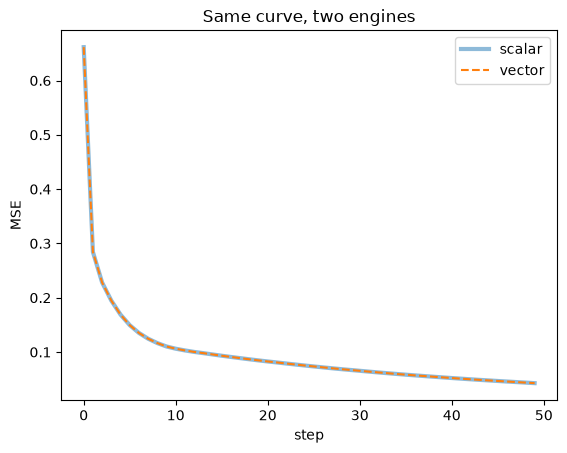

In [5]:
lr, steps = 0.05, 50
s_hist, v_hist = [], []

for _ in range(steps):
    for net, loss_fn, hist in [(snet, scalar_loss, s_hist), (vnet, vector_loss, v_hist)]:
        net.zero_grad()
        loss = loss_fn(net)
        loss.backward()
        for p in net.parameters():
            p.data += -lr * p.grad
        hist.append(float(loss.data))

print(f"max |loss diff| over training: {np.abs(np.array(s_hist) - np.array(v_hist)).max():.2e}")

plt.plot(s_hist, label="scalar", lw=3, alpha=0.5)
plt.plot(v_hist, "--", label="vector")
plt.xlabel("step"); plt.ylabel("MSE"); plt.legend(); plt.title("Same curve, two engines")
plt.show()

## Why bother: speed

This is the reason for the vector engine. The scalar graph has one node per multiply and add, while the vector graph has a handful of nodes per layer. The gap grows quickly with the batch size and layer width.

In [6]:
rng = np.random.default_rng(0)
X_big = rng.normal(size=(200, 3))
Y_big = rng.normal(size=(200, 1))
big_nouts = [16, 16, 1]

snet_big, vnet_big = SMLP(nin, big_nouts), VMLP(nin, big_nouts)

t0 = time.perf_counter()
losses = [(snet_big(x) - y) ** 2 for x, y in zip(X_big.tolist(), Y_big.ravel().tolist())]
(sum(losses) * (1.0 / len(losses))).backward()
t_scalar = time.perf_counter() - t0

t0 = time.perf_counter()
((vnet_big(VValue(X_big)) - VValue(Y_big)) ** 2).mean().backward()
t_vector = time.perf_counter() - t0

print(f"scalar: {t_scalar * 1e3:8.1f} ms")
print(f"vector: {t_vector * 1e3:8.1f} ms  ({t_scalar / t_vector:.0f}x faster)")

scalar:    399.0 ms
vector:      0.3 ms  (1364x faster)
